In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

## Load Experiment

First, we load the experiment from the `results` folder. Each experiment is collected into a single `.parquet` file. Its rows contain recognition results for each configuration (combination) and each fold (flattened).

In [5]:
# Configuration which experiment should be loaded.
EXPERIMENT_NAME = "arcface_against_clear_gallery"
RESULTS_PATH = Path("../../results")

PosixPath('../../results')

In [6]:
# Load the experiment dataset.
EXPERIMENT_PATH = RESULTS_PATH / f"{EXPERIMENT_NAME}.parquet"
EXPERIMENT_DATA = pd.read_parquet(EXPERIMENT_PATH)
EXPERIMENT_DATA

,top-1,top-5,top-10,frame-top-1,fold,gallery_frame_anonymization,gallery_frame_embedding,gallery_frame_aggregation,samples_frame_anonymization,samples_frame_embedding,samples_frame_aggregation,pipeline
0,0.956522,0.972332,0.974967,0.948644,1,none,arcface,video_none,none,arcface,video_none,frame
1,0.966216,0.978041,0.981419,0.958601,2,none,arcface,video_none,none,arcface,video_none,frame
2,0.959335,0.966728,0.968577,0.953381,3,none,arcface,video_none,none,arcface,video_none,frame
3,0.811594,0.906456,0.931489,0.745191,1,none,arcface,video_none,gaussianblur,arcface,video_none,frame
4,0.854730,0.940878,0.954392,0.799595,2,none,arcface,video_none,gaussianblur,arcface,video_none,frame
5,0.817006,0.929760,0.937153,0.765333,3,none,arcface,video_none,gaussianblur,arcface,video_none,frame
6,0.006588,0.014493,0.030303,0.004154,1,none,arcface,video_none,blackbar,arcface,video_none,frame
7,0.001689,0.008446,0.021959,0.002026,2,none,arcface,video_none,blackbar,arcface,video_none,frame
8,0.001848,0.007394,0.016636,0.002026,3,none,arcface,video_none,blackbar,arcface,video_none,frame
9,0.019763,0.057971,0.096179,0.018108,1,none,arcface,video_none,pixelation,arcface,video_none,frame


## Visualize accuracy

The following plots show the mean accuracy for each combination of (sample) anonymization method and (gallery) aggregation method. The first plot aggregates the predictions based on their confidence before classifying. The latter does not and instead takes the mean accuracy over all single-frame classifications.

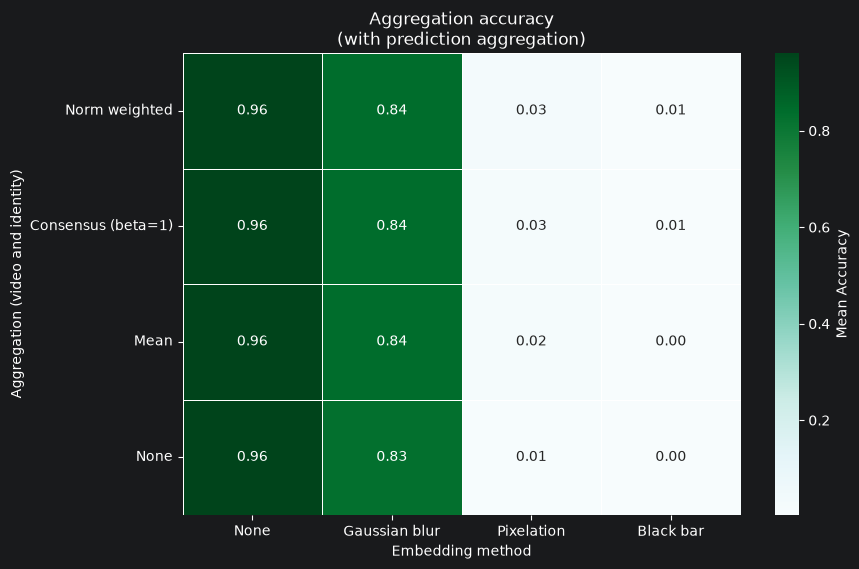

In [18]:
results = EXPERIMENT_DATA.replace({
    "samples_frame_anonymization": {
        "none": "None",
        "gaussianblur": "Gaussian blur",
        "blackbar": "Black bar",
        "pixelation": "Pixelation",
    },
    "gallery_frame_aggregation": {
        "video_none": "None",
        "identity_pooling_mean": "Mean",
        "identity_consensus_beta1": "Consensus (beta=1)",
        "identity_normweighted": "Norm weighted",
    }
})

agg_order = results.groupby("gallery_frame_aggregation")["top-1"].mean().sort_values(ascending=False).index
embedding_order = results.groupby("samples_frame_anonymization")["top-1"].mean().sort_values(ascending=False).index

pivot_agg_embed = results.pivot_table(
    index="gallery_frame_aggregation",
    columns="samples_frame_anonymization",
    values="top-1",
    aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy\n(with prediction aggregation)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video and identity)")
plt.show()

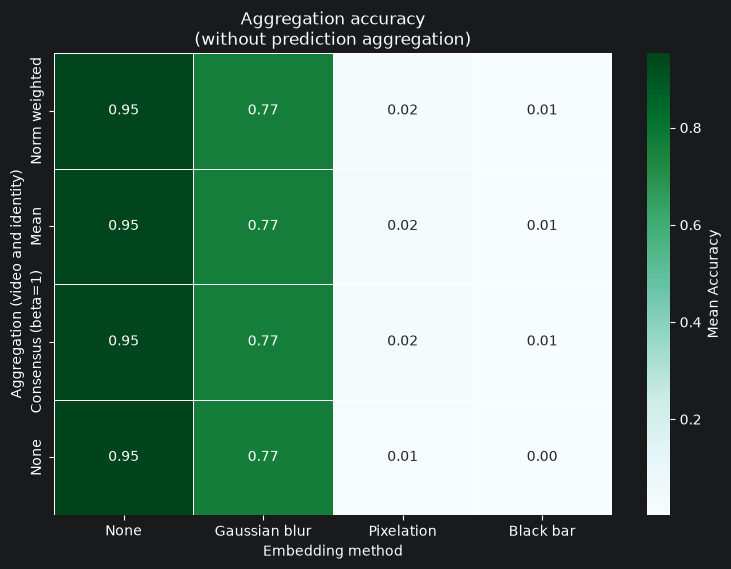

In [19]:
results = EXPERIMENT_DATA.replace({
    "samples_frame_anonymization": {
        "none": "None",
        "gaussianblur": "Gaussian blur",
        "blackbar": "Black bar",
        "pixelation": "Pixelation",
    },
    "gallery_frame_aggregation": {
        "video_none": "None",
        "identity_pooling_mean": "Mean",
        "identity_consensus_beta1": "Consensus (beta=1)",
        "identity_normweighted": "Norm weighted",
    }
})

agg_order = results.groupby("gallery_frame_aggregation")["frame-top-1"].mean().sort_values(ascending=False).index
embedding_order = results.groupby("samples_frame_anonymization")["frame-top-1"].mean().sort_values(ascending=False).index

pivot_agg_embed = results.pivot_table(
    index="gallery_frame_aggregation",
    columns="samples_frame_anonymization",
    values="frame-top-1",
    aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy\n(without prediction aggregation)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video and identity)")
plt.show()